In [22]:
import pandas as pd
import numpy as np

flights = pd.read_csv("flights.csv", nrows=50000)

print("Dataset loaded:", flights.shape)

Dataset loaded: (50000, 31)


In [23]:
print(flights.isnull().sum()[flights.isnull().sum() > 0])

TAIL_NUMBER               59
DEPARTURE_TIME          1104
DEPARTURE_DELAY         1104
TAXI_OUT                1127
WHEELS_OFF              1127
ELAPSED_TIME            1247
AIR_TIME                1247
WHEELS_ON               1161
TAXI_IN                 1161
ARRIVAL_TIME            1161
ARRIVAL_DELAY           1247
CANCELLATION_REASON    48862
AIR_SYSTEM_DELAY       34592
SECURITY_DELAY         34592
AIRLINE_DELAY          34592
LATE_AIRCRAFT_DELAY    34592
WEATHER_DELAY          34592
dtype: int64


In [24]:
# Remove columns that are not useful for prediction
flights = flights.drop(columns=[
    "CANCELLATION_REASON",
    "AIR_SYSTEM_DELAY",
    "SECURITY_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "WEATHER_DELAY"
])

# Remove cancelled flights
flights = flights[flights["CANCELLED"] == 0].copy()

# Remove rows with missing departure delay
flights = flights.dropna(subset=["DEPARTURE_DELAY"])

# Fill missing tail numbers with "Unknown"
flights["TAIL_NUMBER"] = flights["TAIL_NUMBER"].fillna("Unknown")

print("Remaining missing values:")
print(flights.isnull().sum()[flights.isnull().sum() > 0])

print("Dataset shape:", flights.shape)

Remaining missing values:
ELAPSED_TIME     109
AIR_TIME         109
WHEELS_ON         23
TAXI_IN           23
ARRIVAL_TIME      23
ARRIVAL_DELAY    109
dtype: int64
Dataset shape: (48862, 25)


In [25]:
flights = flights.dropna(subset=[
    "ELAPSED_TIME",
    "AIR_TIME",
    "ARRIVAL_DELAY",
    "WHEELS_ON",
    "TAXI_IN",
    "ARRIVAL_TIME"
])

print("Remaining missing values:", flights.isnull().sum().sum())
print("Dataset shape:", flights.shape)

Remaining missing values: 0
Dataset shape: (48753, 25)


In [26]:
print("Duplicates:", flights.duplicated().sum())

flights = flights.drop_duplicates()

print("Dataset shape:", flights.shape)

Duplicates: 0
Dataset shape: (48753, 25)


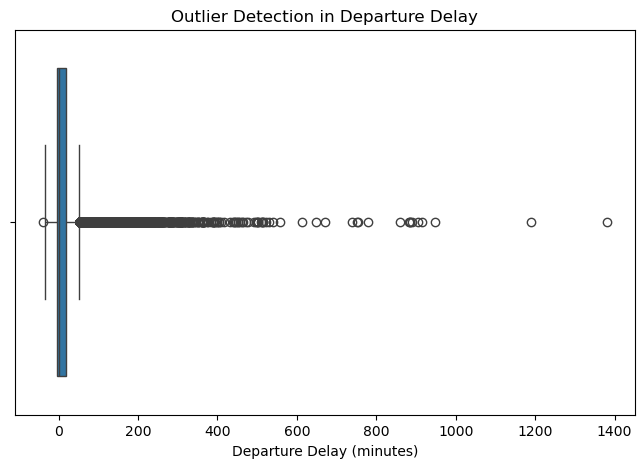

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=flights, x="DEPARTURE_DELAY")

plt.title("Outlier Detection in Departure Delay")
plt.xlabel("Departure Delay (minutes)")
plt.show()

In [28]:
Q1 = flights["DEPARTURE_DELAY"].quantile(0.25)
Q3 = flights["DEPARTURE_DELAY"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = flights[
    (flights["DEPARTURE_DELAY"] < lower_limit) |
    (flights["DEPARTURE_DELAY"] > upper_limit)
]

print("Number of outliers:", len(outliers))

Lower limit: -36.0
Upper limit: 52.0
Number of outliers: 4746


In [29]:
flights_clean = flights.copy()

print("Rows before outlier handling:", len(flights_clean))
print("Rows retained:", len(flights_clean))

Rows before outlier handling: 48753
Rows retained: 48753


In [30]:
flights_clean = pd.get_dummies(
    flights_clean,
    columns=["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"],
    dtype=int
)

print(flights_clean.head())
print("Dataset shape:", flights_clean.shape)

   YEAR  MONTH  DAY  DAY_OF_WEEK  FLIGHT_NUMBER TAIL_NUMBER  \
0  2015      1    1            4             98      N407AS   
1  2015      1    1            4           2336      N3KUAA   
2  2015      1    1            4            840      N171US   
3  2015      1    1            4            258      N3HYAA   
4  2015      1    1            4            135      N527AS   

   SCHEDULED_DEPARTURE  DEPARTURE_TIME  DEPARTURE_DELAY  TAXI_OUT  ...  \
0                    5          2354.0            -11.0      21.0  ...   
1                   10             2.0             -8.0      12.0  ...   
2                   20            18.0             -2.0      16.0  ...   
3                   20            15.0             -5.0      15.0  ...   
4                   25            24.0             -1.0      11.0  ...   

   DESTINATION_AIRPORT_TYR  DESTINATION_AIRPORT_TYS  DESTINATION_AIRPORT_UST  \
0                        0                        0                        0   
1               

In [31]:
flights_clean["DELAYED"] = (
    flights_clean["DEPARTURE_DELAY"] >= 15
).astype(int)

print(flights_clean["DELAYED"].value_counts())

DELAYED
0    34494
1    14259
Name: count, dtype: int64


In [32]:
features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE",
    "SCHEDULED_TIME",
    "DISTANCE"
]

X = flights_clean[features].copy()
y = flights_clean["DELAYED"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (48753, 6)
Target: (48753,)


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 39002
Testing rows: 9751


In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Standardization completed!")

Standardization completed!


In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [36]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7231053225310224

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.94      0.83      6899
           1       0.58      0.20      0.29      2852

    accuracy                           0.72      9751
   macro avg       0.66      0.57      0.56      9751
weighted avg       0.69      0.72      0.67      9751


Confusion Matrix:
[[6492  407]
 [2293  559]]


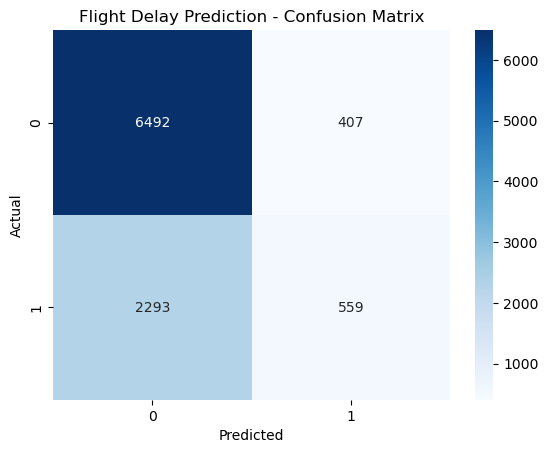

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Flight Delay Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [38]:
print("Dataset shape:", flights_clean.shape)
print("Missing values:", flights_clean.isnull().sum().sum())
print("Duplicate rows:", flights_clean.duplicated().sum())

Dataset shape: (48753, 660)
Missing values: 0
Duplicate rows: 0


In [39]:
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Target classes:")
print(y.value_counts())

Training data shape: (39002, 6)
Testing data shape: (9751, 6)
Target classes:
DELAYED
0    34494
1    14259
Name: count, dtype: int64


In [40]:
print("Rows before outlier removal:", len(flights))
print("Rows after outlier removal:", len(flights_clean))
print("Rows removed:", len(flights) - len(flights_clean))

Rows before outlier removal: 48753
Rows after outlier removal: 48753
Rows removed: 0
